In [1]:
from pathlib import Path

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd

required_files = {
    "Vocabulary": "data/vocab.json",
    "Token IDs": "data/token_ids.pt",
    "Configuration": "data/config.json",

    "Trigram": "models/ngram_model.pkl",
    "RNN": "models/rnn_best.pt",
    "LSTM": "models/lstm_best.pt",
    "Transformer": "models/transformer_best.pt",

    "Skip-gram embeddings": "models/skipgram_embeddings.pt",
    "Skip-gram LSTM": "models/lstm_skipgram_best.pt",

    "GloVe embeddings": "models/glove_embeddings.pt",
    "GloVe LSTM": "models/lstm_glove_best.pt",

    "Part I results": "results/part1_comparison.json",
    "Part III results": "results/downstream_results.json",

    "Model definitions": "src/language_models.py"
}

missing_files = []

for name, relative_path in required_files.items():
    path = PROJECT_ROOT / relative_path

    if path.exists():
        print(f"[OK]      {name}")
    else:
        print(f"[MISSING] {name}")
        missing_files.append(relative_path)

print("\n" + "=" * 50)

if not missing_files:
    print("All required files found!")
else:
    print(f"{len(missing_files)} files are missing.")
    print("Missing files:", missing_files)

[OK]      Vocabulary
[OK]      Token IDs
[OK]      Configuration
[OK]      Trigram
[OK]      RNN
[OK]      LSTM
[OK]      Transformer
[OK]      Skip-gram embeddings
[OK]      Skip-gram LSTM
[OK]      GloVe embeddings
[OK]      GloVe LSTM
[OK]      Part I results
[MISSING] Part III results
[OK]      Model definitions

1 files are missing.
Missing files: ['results/downstream_results.json']


In [3]:
from pathlib import Path

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd

RESULTS_DIR = PROJECT_ROOT / "results"

expected_figures = [
    "rnn_loss_curve.png",
    "lstm_loss_curve.png",
    "transformer_loss_curve.png",
    "lstm_skipgram_loss_curve.png",
    "lstm_glove_loss_curve.png",
    "downstream_confusion_matrices.png"
]

missing_figures = []

for filename in expected_figures:
    path = RESULTS_DIR / filename

    if path.exists():
        size_kb = path.stat().st_size / 1024
        print(f"[OK] {filename} ({size_kb:.1f} KB)")
    else:
        print(f"[MISSING] {filename}")
        missing_figures.append(filename)

print("\nMissing figures:", len(missing_figures))

[MISSING] rnn_loss_curve.png
[OK] lstm_loss_curve.png (130.9 KB)
[OK] transformer_loss_curve.png (133.0 KB)
[OK] lstm_skipgram_loss_curve.png (135.6 KB)
[OK] lstm_glove_loss_curve.png (138.6 KB)
[OK] downstream_confusion_matrices.png (91.3 KB)

Missing figures: 1


In [4]:
import json

with open(RESULTS_DIR / "rnn_results.json", "r") as f:
    rnn_results = json.load(f)

history = rnn_results["history"]

print("Training losses:", history["train_loss"])
print("Validation losses:", history["val_loss"])
print("Number of epochs:", len(history["train_loss"]))

Training losses: [5.700358653328073, 5.1564815477424935, 4.960466107658519, 4.837055153530098, 4.7448966826552565]
Validation losses: [5.249010854864056, 5.07764945414793, 5.005631249268112, 4.973086743267036, 4.936594150317173]
Number of epochs: 5


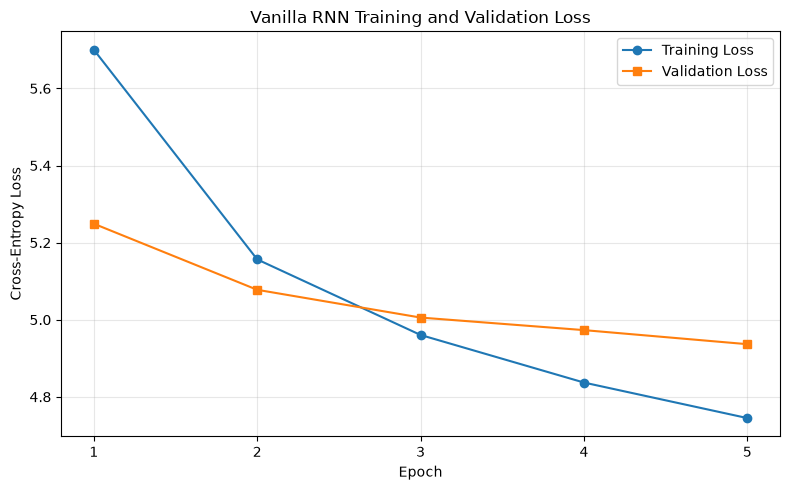

Figure saved: True
Location: c:\Users\User\NUS\DSA NLP\DSA4213_Assignment1\results\rnn_loss_curve.png


In [5]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Vanilla RNN Training and Validation Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

output_path = RESULTS_DIR / "rnn_loss_curve.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", output_path.exists())
print("Location:", output_path)

In [6]:
for filename in expected_figures:
    path = RESULTS_DIR / filename
    print("[OK]" if path.exists() else "[MISSING]", filename)

[OK] rnn_loss_curve.png
[OK] lstm_loss_curve.png
[OK] transformer_loss_curve.png
[OK] lstm_skipgram_loss_curve.png
[OK] lstm_glove_loss_curve.png
[OK] downstream_confusion_matrices.png


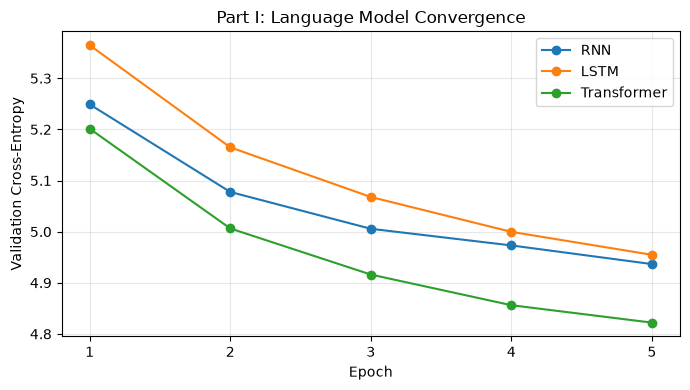

Saved: part1_validation_comparison.png


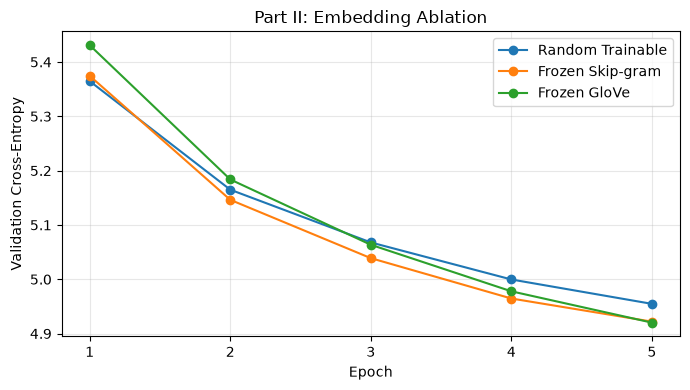

Saved: part2_embedding_comparison.png


In [7]:
import json
import matplotlib.pyplot as plt

comparisons = {
    "part1_validation_comparison.png": {
        "title": "Part I: Language Model Convergence",
        "files": {
            "RNN": "rnn_results.json",
            "LSTM": "lstm_results.json",
            "Transformer": "transformer_results.json"
        }
    },
    "part2_embedding_comparison.png": {
        "title": "Part II: Embedding Ablation",
        "files": {
            "Random Trainable": "lstm_results.json",
            "Frozen Skip-gram": "lstm_skipgram_results.json",
            "Frozen GloVe": "lstm_glove_results.json"
        }
    }
}

for filename, config in comparisons.items():
    plt.figure(figsize=(7, 4))

    for name, result_file in config["files"].items():
        with open(RESULTS_DIR / result_file) as f:
            results = json.load(f)

        train_losses = results["history"]["train_loss"]
        val_losses = results["history"]["val_loss"]
        epochs = range(1, len(train_losses) + 1)

        plt.plot(
            epochs, val_losses,
            marker="o", label=name
        )

    plt.title(config["title"])
    plt.xlabel("Epoch")
    plt.ylabel("Validation Cross-Entropy")
    plt.xticks(range(1, 6))
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        RESULTS_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    print("Saved:", filename)

In [8]:
with open(RESULTS_DIR / "ngram_results.json") as f:
    ngram_results = json.load(f)

print(
    "N-gram counting time:",
    ngram_results["counting_time_seconds"],
    "seconds"
)

N-gram counting time: 1.2784480999980588 seconds
